In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as pl

# Get TESS light curve

In [3]:
import lightkurve as lk

search_result = lk.search_lightcurve('HD 39091', mission='TESS', author='SPOC')
search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 01,2018,SPOC,120,261136679,0.0
1,TESS Sector 04,2018,SPOC,120,261136679,0.0
2,TESS Sector 08,2019,SPOC,120,261136679,0.0
3,TESS Sector 11,2019,SPOC,120,261136679,0.0
4,TESS Sector 12,2019,SPOC,120,261136679,0.0
5,TESS Sector 13,2019,SPOC,120,261136679,0.0
...,...,...,...,...,...,...
26,TESS Sector 66,2023,SPOC,20,261136679,0.0
27,TESS Sector 66,2023,SPOC,120,261136679,0.0


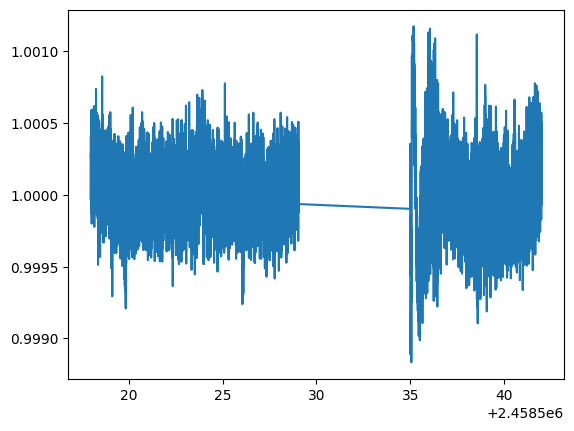

In [4]:
lc = search_result[2].download()
lc = lc.remove_outliers()
lc = lc.remove_nans()

df_all = pd.DataFrame({'time':lc.time.value+ 2457000.0, \
                    'flux':lc.pdcsap_flux.value / np.median(lc.pdcsap_flux.value),\
                    'err':lc.pdcsap_flux_err.value / np.median(lc.pdcsap_flux.value)})
pl.plot(df_all['time'], df_all['flux'])

In [5]:
time = np.array(df_all['time'])
flux = np.array(df_all['flux'])
err = np.array(df_all['err'])

In [6]:
from uncertainties import ufloat

T0_pr = ufloat(2458325.50400, 0.0012)      #T0_predict
P_pr = ufloat(6.2679, 0.00046)             #Period_predict

n_tran_start=np.ceil((time[0]-T0_pr.n)/P_pr.n)  #transit number
n_tran_end=np.floor((time[-1]-T0_pr.n)/P_pr.n)
n_tran=np.arange(n_tran_start, n_tran_end+1, 1)
n_tran

array([31., 32., 33., 34.])

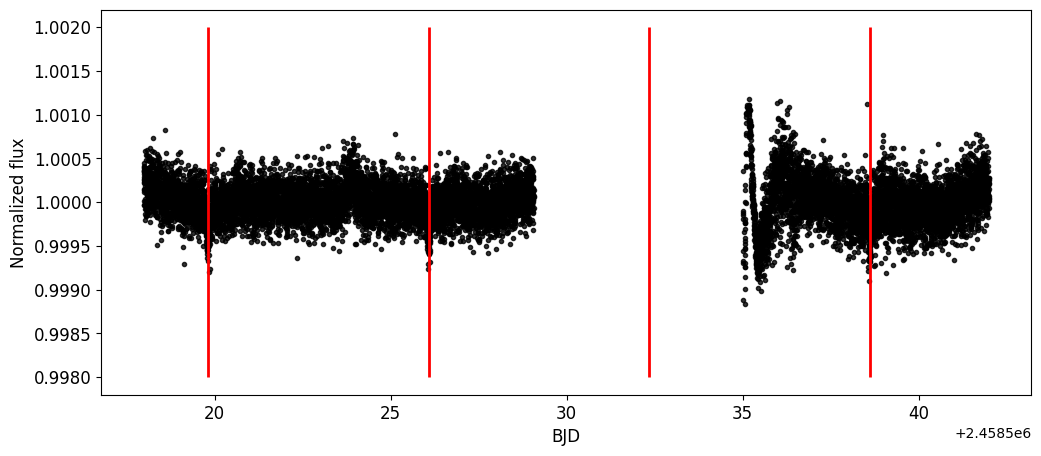

In [7]:
f, ax = pl.subplots(figsize=(12,5))

pl.xlabel('BJD',fontsize=12)
pl.ylabel('Normalized flux',fontsize=12)
pl.tick_params(labelsize=12)

pl.plot(time,flux,".", color='k', alpha=0.8)

for n in n_tran:
    ax.vlines(T0_pr.n+P_pr.n*n, 0.998, 1.002, color='r', lw=2)

f.savefig('output/K2-25_LC_whole.png')

In [8]:
n_tran = [31, 32, 34]

In [9]:
#extract transit dataset

dfs_transit = []

i=0
for n in n_tran:
    df = df_all[(df_all['time']>(T0_pr+P_pr*n-0.3))&(df_all['time']<(T0_pr+P_pr*n+0.3))]
    dfs_transit.append(df)

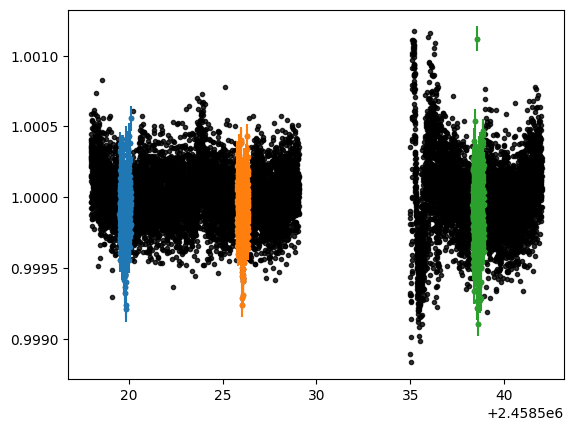

In [10]:
pl.plot(time,flux,".", color='k', alpha=0.8)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    pl.errorbar(df['time'], df['flux'], df['err'], fmt='.')

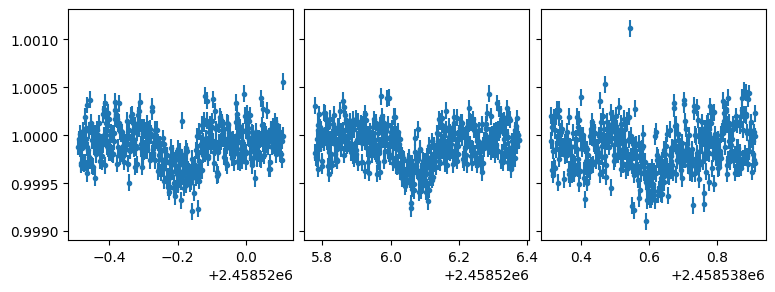

In [11]:
f, axs = pl.subplots(1, 3, figsize=(9,3), sharey=True)
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    axs[int(i%3)].errorbar(df['time'], df['flux'], df['err'], fmt='.')

# imput parameters
From Huang et al. (2018)

In [12]:
k_pr = ufloat(0.01703, 0.00025) #Rp/Rs
a_pr = ufloat(13.38, 0.26) #a/Rs
b_pr = ufloat(0.59, 0.02)  #impact parameter, b

In [52]:
from ldtk import LDPSetCreator
from ldtk.filters import tess

teff, uteff = 6037, 45
feh, ufeh   = 0.08,  0.03
logg,ulogg =  4.42, 0.03

sc = LDPSetCreator(teff=(teff,uteff), logg=(logg,ulogg), z=(feh,ufeh), filters=[tess])
ps = sc.create_profiles(nsamples=2000)
ps.resample_linear_z(100)
qd_c,qd_e = ps.coeffs_qd(do_mc=True, n_mc_samples=10000)

u1, u2 = list(qd_c[0])
u1_err, u2_err = list(qd_e[0])

In [53]:
def u_to_q(u1, u2):
    q1 = (u1 + u2)**2
    q2 = u1 / (2 * (u1 + u2))
    return q1, q2

def q_to_u(q1, q2):
    u1 = 2 * np.sqrt(q1) * q2
    u2 = np.sqrt(q1) * (1 - 2*q2)
    return u1, u2

In [148]:
q1_init, q2_init = u_to_q(u1, u2)
q1, q2

(0.1, 0.1)

# Transit model 

In [237]:
import batman
def transit_model_batman(parameters, t):

    t0, p, a, b, k, q1, q2 = parameters
    
    inc= np.arccos(b/a)*180/np.pi
    u1, u2 = q_to_u(q1, q2)
    
    params = batman.TransitParams()
    params.t0 = t0                      #time of inferior conjunction
    params.per = p                     #orbital period
    params.rp = k                 #planet radius (in units of stellar radii)
    params.a = a                      #semi-major axis (in units of stellar radii)
    params.inc = inc                     #orbital inclination (in degrees)
    params.ecc = 0.                      #eccentricity
    params.w = 90.                       #longitude of periastron (in degrees)
    params.u = [u1, u2]                #limb darkening coefficients [u1, u2]
    params.limb_dark = "quadratic" 

    m = batman.TransitModel(params, np.array(t))  
    flux = m.light_curve(params)
    return flux

In [278]:
from celerite.modeling import Model
class MeanModel(Model):
    parameter_names = ('T0','P','a','b','k','q1','q2')

    def get_value(self, t):
        params = [self.T0, self.P, self.a, self.b, self.k, self.q1, self.q2]
        return transit_model_batman(params, t)
        
transit_model = MeanModel(T0=T0_pr.n, P=P_pr.n, a=a_pr.n, b=b_pr.n, k=k_pr.n, q1=q1_init, q2=q2_init)

In [281]:
transit_model.get_parameter_dict()

OrderedDict([('T0', 2458325.504),
             ('P', 6.2679),
             ('a', 13.38),
             ('b', 0.59),
             ('k', 0.01703),
             ('q1', 0.288140506484591),
             ('q2', 0.36637666107630207)])

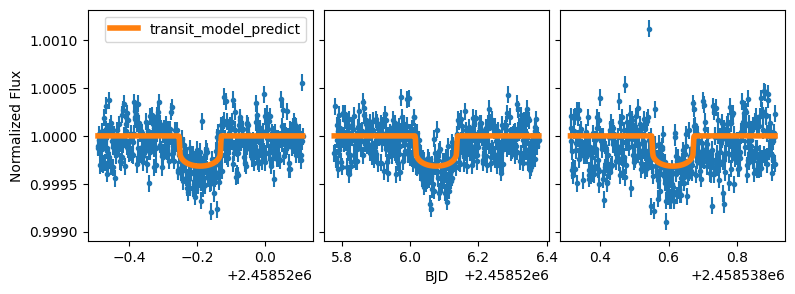

In [282]:
f, axs = pl.subplots(1, 3, figsize=(9,3), sharey=True)
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    axs[int(i%3)].errorbar(df['time'], df['flux'], df['err'], fmt='.', zorder=0)
    
    t_model=transit_model.get_value(df['time'])
    
    axs[int(i%3)].plot(df['time'],t_model, '-', lw=4, label='transit_model_predict', zorder=1)
axs[1].set_xlabel('BJD')
axs[0].set_ylabel('Normalized Flux')
axs[0].legend()
    
#f.savefig('output/TOI519_transit_predict.png')

# Gaussian Process

In [283]:
import celerite
from celerite import terms

In [464]:
bounds1 = dict(log_sigma=(-5, 5), log_rho=(0, 5)) 
term1 = terms.Matern32Term(log_sigma=-1, log_rho=2, bounds=bounds)

bounds2 = dict(log_sigma=(-10, -5)) 
term2 = terms.JitterTerm(log_sigma=-8)

kernel = term1 + term2

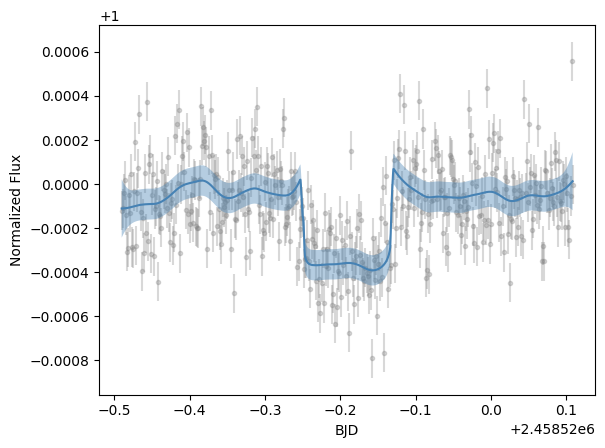

In [465]:
df = dfs_transit[0]
time = np.array(df['time'])
flux= np.array(df['flux'])
err = np.array(df['err'])

t_fine=np.linspace(time[0], time[-1], 1000) 

gp = celerite.GP(kernel, mean=transit_model)
gp.compute(time, err) 
pred_mean, pred_var = gp.predict(resid, t_fine, return_var=True)
pred_std = np.sqrt(pred_var)

pl.errorbar(time, flux, err, fmt='.', zorder=0, color='gray', alpha=0.3)

pl.plot(t_fine, pred_mean+t_model_fine, '-', color='steelblue')
pl.fill_between(t_fine, 
                pred_mean+pred_std+t_model_fine, 
                pred_mean-pred_std+t_model_fine,  
                alpha=0.4, color='steelblue', edgecolor="none")

pl.xlabel('BJD')
pl.ylabel('Normalized Flux')

f.savefig('output/PiMen_transit_GP_fixhyperparam.png')

In [466]:
gp.log_likelihood(flux)

2949.1640512861654

In [469]:
gp.get_parameter_dict()

OrderedDict([('kernel:terms[0]:log_sigma', -1.0),
             ('kernel:terms[0]:log_rho', 2.0),
             ('kernel:terms[1]:log_sigma', -8.0)])

In [494]:
theta_init = [0, 2, -8] #hyper parameters (log_sigma, log_rho)
params_all_init = theta_init+t_params_init
params_name = 'sigma,rho,jitter,T0,P,a_Rs,b,Rp_Rs,q1,q2'.split(',')
#params_all_pr

In [495]:
def GP_predict(df, params):

    #data
    time = np.array(df['time'])
    flux= np.array(df['flux'])
    err = np.array(df['err'])

    t_fine=np.linspace(time[0], time[-1], 1000) 

    #param
    theta=params[:3]
    t_params = params[3:]
    
    transit_model = MeanModel(*t_params)

    #GP
    gp = celerite.GP(kernel, mean=transit_model)
    gp.compute(time, err) 
    gp.set_parameter_vector(theta)
    
    pred_mean, pred_var = gp.predict(resid, t_fine, return_var=True)
    pred_std = np.sqrt(pred_var)
    
    pred_df=pd.DataFrame({'t_fine':t_fine,'pred_baseline':pred_mean,'pred_mean':pred_mean+t_model_fine,'pred_std':pred_std})

    return pred_df

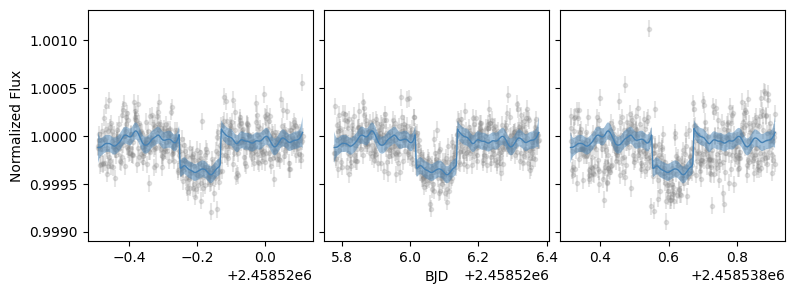

In [496]:
#example of GP modeling, with fixed hyper parameters (sigma, rho)

f, axs = pl.subplots(1, 3, figsize=(9,3), sharey=True)
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    axs[int(i%3)].errorbar(df['time'], df['flux'], df['err'], fmt='.', color='gray', alpha=0.2, zorder=0)
    
    pred_df = GP_predict(df, params_all_init)
    axs[int(i%3)].plot(pred_df['t_fine'], pred_df['pred_mean'], '-', color='steelblue', lw=1, zorder=1)
    axs[int(i%3)].fill_between(pred_df['t_fine'], 
                               pred_df['pred_mean']+pred_df['pred_std'],
                               pred_df['pred_mean']-pred_df['pred_std'],
                               alpha=0.5, color='steelblue', edgecolor="none")
    
axs[1].set_xlabel('BJD')
axs[0].set_ylabel('Normalized Flux')
f.savefig('output/PiMen_transit_GP_fixhyperparam_3transit.png')

In [479]:
from scipy import stats

def logprior(t_params):
    T0, P, a, b, k, q1, q2= t_params
    
    lp = 0
    
    if not 0<a<100:
        return -np.inf
    
    if not all (0<x<1 for x in [b, k, q1, q2]):
        return -np.inf
    
    lp += stats.norm.logpdf(P, loc=P_pr.n, scale=P_pr.s)
    lp += stats.norm.logpdf(T0, loc=T0_pr.n, scale=T0_pr.s)
    lp += stats.norm.logpdf(q1, loc=q1_pr, scale=0.1)
    lp += stats.norm.logpdf(q2, loc=q2_pr, scale=0.1)
    lp += stats.norm.logpdf(k, loc=k_pr.n, scale=k_pr.s)
    
    return lp
    
def loglike_gp(params):
    theta = params[:3]
    t_params = params[3:]

    lp = logprior(t_params)
    ll_sum = 0
    
    #data
    for df in dfs_transit:
        time = np.array(df['time'])
        flux = np.array(df['flux'])
        err = np.array(df['err'])
        
        transit_model = MeanModel(*t_params)
        gp = celerite.GP(kernel, mean=transit_model, fit_mean=True)
        gp.set_parameter_vector(params)
    
        lp_gp = gp.log_prior()    
        if not np.isfinite(lp_gp):
            return -np.inf
        
        gp.compute(time, err)
        ll_sum += gp.log_likelihood(flux) + lp_gp
        
    return ll_sum + lp

#nll = lambda *args: -log_probability(*args)

In [480]:
loglike_gp(params_all_init)

8842.47768908537

# MCMC

In [481]:
import emcee

params  = params_all_init
ndim = len(params)
nwalkers = 64
nsteps=1000

In [482]:
sampler = emcee.EnsembleSampler(nwalkers, ndim, loglike_gp)

p0 = [params +  1e-5 * np.random.randn(ndim) for i in range(nwalkers)]
sampler.run_mcmc(p0, nsteps, progress=True)
samples = sampler.get_chain(discard=0, thin=1)

100%|███████████████████████████████████████| 1000/1000 [01:20<00:00, 12.47it/s]


In [501]:
R=6300

In [502]:
1386000000 / (np.pi * R**3)

0.0017643783058814298

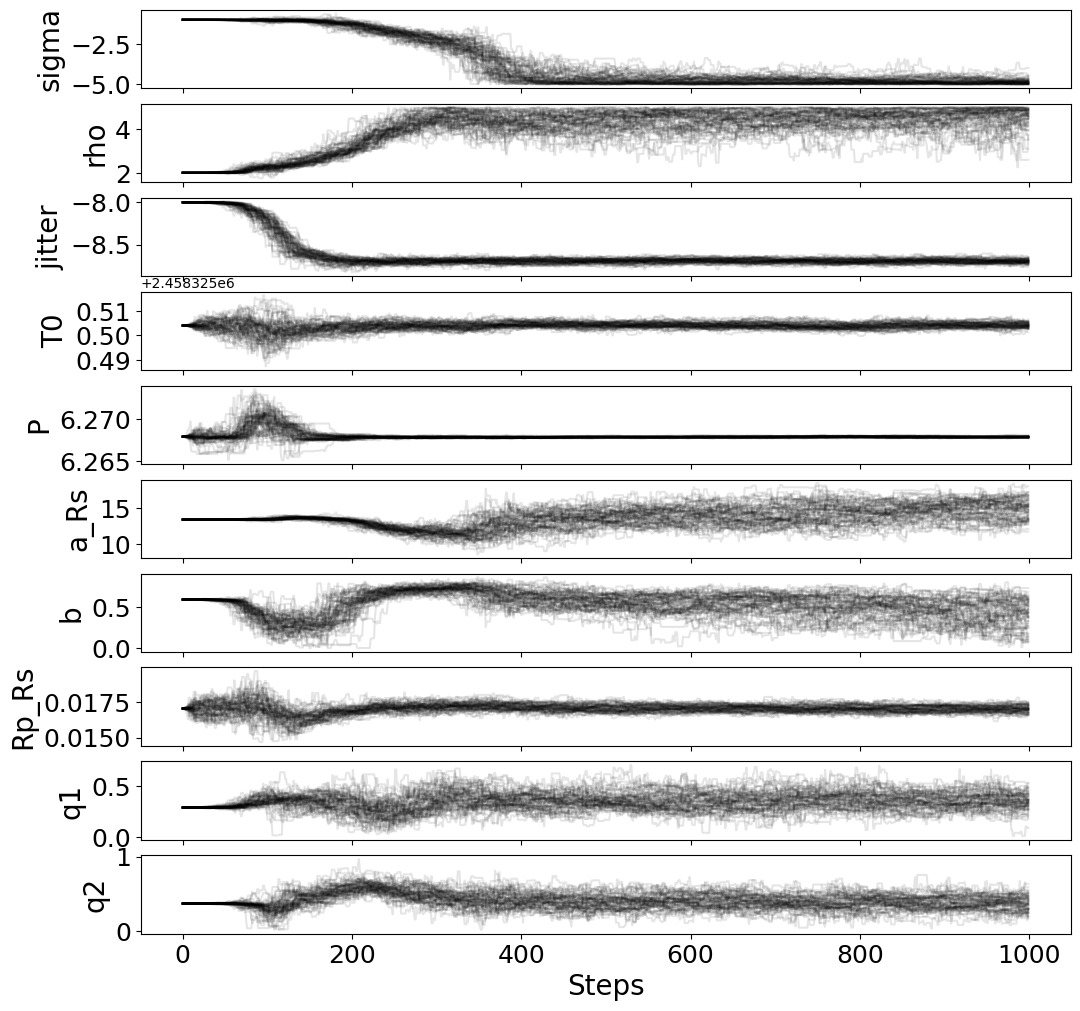

In [483]:
f, ax = pl.subplots(ndim, 1, figsize=(10*1.2,ndim*1.2))

for i in range(ndim):
    ax[i].plot(samples[:, :, i], color='k', alpha=0.1)
    
    if i==(ndim-1):
        pl.setp(ax[i].get_xticklabels(), visible=True, fontsize=18)
        ax[i].set_xlabel('Steps', fontsize=20)
    else:
        pl.setp(ax[i].get_xticklabels(), visible=False)
    
    pl.setp(ax[i].get_yticklabels(), fontsize=18)
    ax[i].set_ylabel(params_name[i],fontsize=20)
    
#f.savefig('output/TOI519_chain.png')

In [484]:
flat_samples = sampler.get_chain(discard=500, thin=10, flat=True)

In [485]:
best_params=[]
best_params_err = []

for i in range(ndim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)

    best_params.append(mcmc[1])
    best_params_err.append(np.mean(q))

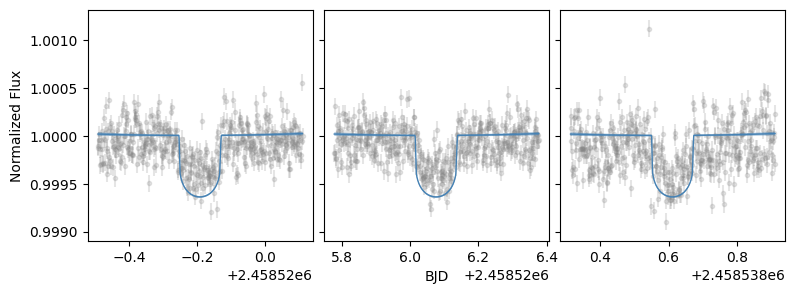

In [490]:
f, axs = pl.subplots(1, 3, figsize=(9,3), sharey=True)
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    axs[int(i%3)].errorbar(df['time'], df['flux'], df['err'], fmt='.', color='gray', alpha=0.2, zorder=0)
    
    pred_df = GP_predict(df, best_params)
    
    axs[int(i%3)].plot(pred_df['t_fine'], pred_df['pred_mean'], '-', color='steelblue', lw=1, zorder=1)
    axs[int(i%3)].fill_between(pred_df['t_fine'], 
                               pred_df['pred_mean']+pred_df['pred_std'],
                               pred_df['pred_mean']-pred_df['pred_std'],
                               alpha=0.5, color='steelblue', edgecolor="none")
    
axs[1].set_xlabel('BJD')
axs[0].set_ylabel('Normalized Flux')
f.savefig('output/PiMen_transit_GP_bestparam_3transit.png')

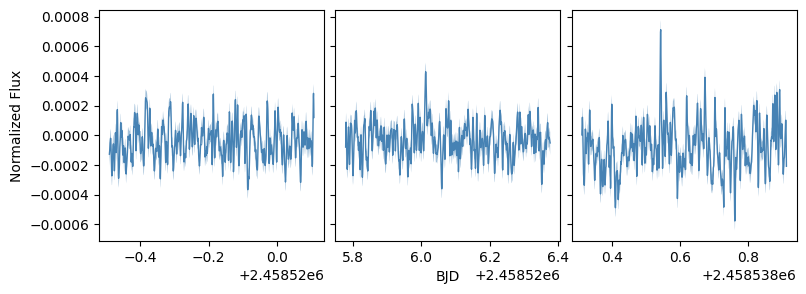

In [236]:
f, axs = pl.subplots(1, 3, figsize=(9,3), sharey=True)
pl.subplots_adjust(wspace=0.05)

for i in range(len(n_tran)):
    df = dfs_transit[i]
    #axs[int(i%3)].errorbar(df['time'], df['flux']-, df['err'], fmt='.', color='gray', alpha=0.2, zorder=0)
    
    pred_df = GP_predict(df, best_params)
    
    axs[int(i%3)].plot(pred_df['t_fine'], pred_df['pred_baseline'], '-', color='steelblue', lw=1, zorder=1)
    axs[int(i%3)].fill_between(pred_df['t_fine'], 
                               pred_df['pred_baseline']+pred_df['pred_std'],
                               pred_df['pred_baseline']-pred_df['pred_std'],
                               alpha=0.5, color='steelblue', edgecolor="none")
    
axs[1].set_xlabel('BJD')
axs[0].set_ylabel('Normalized Flux')
f.savefig('output/PiMen_transit_GP_bestparam_3transit.png')